# Projeto 5 — Transformers: classificação de emoções em textos

**UC de Redes Neurais**

O objetivo é classificar emoções em textos em inglês com o dataset [dair-ai/emotion](https://huggingface.co/datasets/dair-ai/emotion). Utilizamos DistilBERT com fine-tuning em PyTorch e Hugging Face Transformers.

O notebook contempla a preparação do ambiente, a exploração dos dados, a tokenização, o carregamento do DistilBERT e o treinamento e avaliação do baseline na validação. As classes são **sadness, joy, love, anger, fear e surprise**. O treinamento deve ser executado manualmente; o teste permanece reservado para a comparação final.

No **Google Colab**, execute as células em ordem. É necessário acesso à internet para instalar as dependências e baixar os dados. Esta etapa pode ser executada em CPU.


## Instalação das bibliotecas

O comando instala as dependências que ainda não estiverem disponíveis. PyTorch e Transformers também preparam o ambiente para as etapas futuras.


In [1]:
%pip install -q torch transformers datasets pandas matplotlib numpy accelerate scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\davis\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Importações e reprodutibilidade

Fixamos a semente em **42** para Python, NumPy e PyTorch. Isso ajuda na reprodutibilidade; resultados exatos podem variar entre versões e dispositivos.


In [2]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import display

SEMENTE = 42

random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)

# Configura também as sementes e o cuDNN, caso haja GPU.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMENTE)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Semente configurada: {SEMENTE}")


Semente configurada: 42


## Carregamento do dataset

Usamos a configuração **`split`**, que fornece as divisões originais `train`, `validation` e `test`. Não criamos novas divisões nem alteramos os exemplos.

Cada registro contém um texto (`text`) e um rótulo numérico (`label`). Obtemos os nomes das emoções dos metadados do dataset.


In [3]:
# O segundo argumento seleciona a configuração do dataset.
dataset = load_dataset("dair-ai/emotion", "split")

divisoes = {
    "train": "Treinamento",
    "validation": "Validação",
    "test": "Teste",
}

nomes_classes = dataset["train"].features["label"].names
tabela_classes = pd.DataFrame({
    "Rótulo": range(len(nomes_classes)),
    "Emoção": nomes_classes,
})
display(tabela_classes)

# Cópias em DataFrames facilitam a exploração sem alterar o dataset.
dados = {divisao: dataset[divisao].to_pandas() for divisao in divisoes}


README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

C:\Users\davis\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\davis\.cache\huggingface\hub\datasets--dair-ai--emotion. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\davis\AppData\Local\P

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

,Rótulo,Emoção
0,0,sadness
1,1,joy
2,2,love
3,3,anger
4,4,fear
5,5,surprise


## Quantidade de exemplos e visualização dos textos

A tabela mostra o tamanho de cada divisão original. Em seguida, exibimos um exemplo de treinamento por emoção, mantendo os textos em inglês.


In [4]:
quantidades = pd.DataFrame({
    "Divisão": list(divisoes.values()),
    "Exemplos": [len(dataset[divisao]) for divisao in divisoes],
})
display(quantidades)
print(f"Total de exemplos: {quantidades['Exemplos'].sum():,}")

# Seleciona exemplos apenas para exibição; o conjunto permanece completo.
exemplos = (
    dados["train"]
    .groupby("label", sort=True)
    .head(1)
    .sort_values("label")
    .copy()
)
exemplos["Emoção"] = exemplos["label"].map(dict(enumerate(nomes_classes)))
exemplos = exemplos.rename(columns={"text": "Texto", "label": "Rótulo"})

with pd.option_context("display.max_colwidth", None):
    display(exemplos[["Texto", "Rótulo", "Emoção"]].reset_index(drop=True))


,Divisão,Exemplos
0,Treinamento,16000
1,Validação,2000
2,Teste,2000


Total de exemplos: 20,000


,Texto,Rótulo,Emoção
0,i didnt feel humiliated,0,sadness
1,i have been with petronas for years i feel that petronas has performed well and made a huge profit,1,joy
2,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,2,love
3,im grabbing a minute to post i feel greedy wrong,3,anger
4,i feel as confused about life as a teenager or as jaded as a year old man,4,fear
5,ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny,5,surprise


## Distribuição das seis classes

As tabelas apresentam a quantidade e o percentual de cada emoção por divisão. O gráfico compara as quantidades. Essa análise permite identificar possíveis desequilíbrios antes do futuro treinamento.


Quantidade de exemplos por emoção:


,Treinamento,Validação,Teste
Emoção,,,
sadness,4666,550,581
joy,5362,704,695
love,1304,178,159
anger,2159,275,275
fear,1937,212,224
surprise,572,81,66


Percentual por emoção dentro de cada divisão (%):


,Treinamento,Validação,Teste
Emoção,,,
sadness,29.16,27.50,29.05
joy,33.51,35.20,34.75
love,8.15,8.90,7.95
anger,13.49,13.75,13.75
fear,12.11,10.60,11.20
surprise,3.58,4.05,3.30


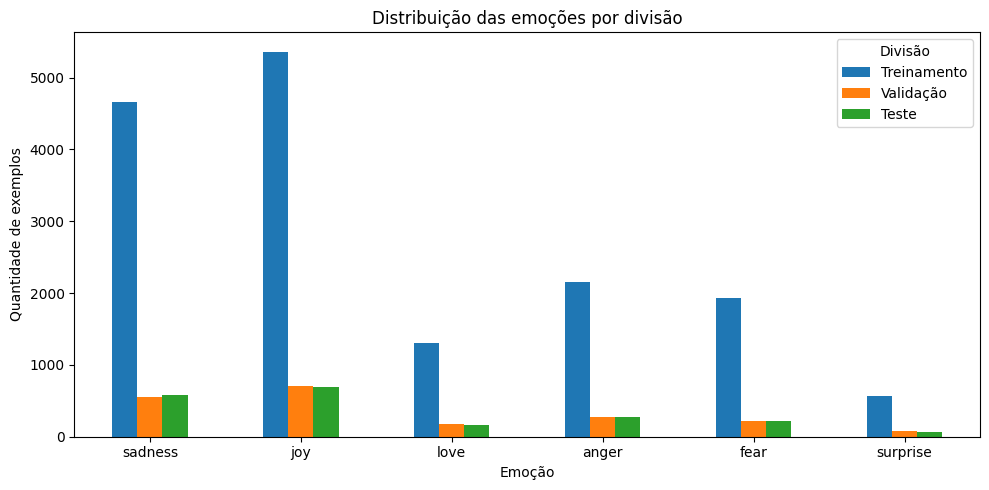

In [5]:
# Reindexar mantém todas as seis classes, mesmo se alguma tiver contagem zero.
contagens = pd.DataFrame({
    nome: dados[divisao]["label"].value_counts().reindex(
        range(len(nomes_classes)), fill_value=0
    )
    for divisao, nome in divisoes.items()
})
contagens.index = pd.Index(nomes_classes, name="Emoção")

percentuais = contagens.div(contagens.sum(axis=0), axis=1).mul(100)

print("Quantidade de exemplos por emoção:")
display(contagens)
print("Percentual por emoção dentro de cada divisão (%):")
display(percentuais.round(2))

ax = contagens.plot.bar(figsize=(10, 5), rot=0)
ax.set_title("Distribuição das emoções por divisão")
ax.set_xlabel("Emoção")
ax.set_ylabel("Quantidade de exemplos")
ax.legend(title="Divisão")
plt.tight_layout()
plt.show()


## Verificação de textos vazios e valores ausentes

Contamos valores ausentes nas colunas `text` e `label` em cada divisão. Também verificamos textos vazios, incluindo aqueles formados apenas por espaços. Valores ausentes são contados separadamente dos textos vazios.

Esta etapa apenas inspeciona os dados; nenhum exemplo será removido, preenchido ou modificado.


In [6]:
verificacoes = []

for divisao, nome in divisoes.items():
    df = dados[divisao]

    # O tipo string preserva ausentes; strip permite detectar só espaços.
    textos_vazios = df["text"].astype("string").str.strip().eq("").fillna(False)

    verificacoes.append({
        "Divisão": nome,
        "Textos ausentes": int(df["text"].isna().sum()),
        "Rótulos ausentes": int(df["label"].isna().sum()),
        "Textos vazios ou só espaços": int(textos_vazios.sum()),
    })

qualidade = pd.DataFrame(verificacoes).set_index("Divisão")
display(qualidade)

if qualidade.to_numpy().sum() == 0:
    print("Não foram encontrados textos vazios nem valores ausentes em text e label.")
else:
    print("Foram encontrados problemas. Revise a tabela antes de avançar no projeto.")


,Textos ausentes,Rótulos ausentes,Textos vazios ou só espaços
Divisão,,,
Treinamento,0,0,0
Validação,0,0,0
Teste,0,0,0


Não foram encontrados textos vazios nem valores ausentes em text e label.


## Tokenização dos textos

Usamos `AutoTokenizer` com o checkpoint **distilbert-base-uncased**. A tokenização mantém a ordem dos exemplos e os rótulos originais, limita as sequências a **128 tokens** (incluindo tokens especiais) e não adiciona padding nesta etapa.

O `DataCollatorWithPadding` fará o **padding dinâmico** até o maior comprimento de cada lote, produzindo tensores PyTorch. A coluna de texto é removida apenas da cópia tokenizada; o dataset original permanece disponível.

A constante `NOME_MODELO` define o checkpoint comum ao tokenizer e ao modelo e deve ser reutilizada posteriormente no baseline e no Optuna. Referência: [classificação de textos com Hugging Face](https://huggingface.co/docs/transformers/tasks/sequence_classification).


In [7]:
from transformers import (
    AutoTokenizer,
    DataCollatorWithPadding,
    AutoModelForSequenceClassification,
)

NOME_MODELO = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(NOME_MODELO)


def tokenizar_textos(exemplos):
    return tokenizer(
        exemplos["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )


# DatasetDict.map aplica a função às três divisões, sem criar novas divisões.
dataset_tokenizado = dataset.map(
    tokenizar_textos,
    batched=True,
    remove_columns=["text"],
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt",
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

C:\Users\davis\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\davis\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

### Exemplo tokenizado e verificação das divisões

Mostramos o texto original, os tokens, seus identificadores e a máscara de atenção. Verificamos a quantidade e a ordem dos rótulos em cada divisão, além dos comprimentos das sequências e máscaras.

Um pequeno lote permite conferir o padding e o formato dos tensores, sem passar dados pelo modelo. O collator renomeia `label` para `labels`, como esperado pelo modelo, preservando os valores.


In [8]:
exemplo_original = dataset["train"][0]
exemplo_tokenizado = dataset_tokenizado["train"][0]

print("Texto original:", exemplo_original["text"])
print("Emoção:", nomes_classes[exemplo_original["label"]])
print("Tokens:", tokenizer.convert_ids_to_tokens(exemplo_tokenizado["input_ids"]))
print("input_ids:", exemplo_tokenizado["input_ids"])
print("attention_mask:", exemplo_tokenizado["attention_mask"])
print("Rótulo preservado:", exemplo_tokenizado["label"])

resumo_tokenizacao = []

assert set(dataset_tokenizado) == set(divisoes)

for divisao, nome in divisoes.items():
    original = dataset[divisao]
    tokenizado = dataset_tokenizado[divisao]

    assert len(tokenizado) == len(original), f"Quantidade alterada em {nome}"
    assert list(tokenizado["label"]) == list(original["label"]), (
        f"Rótulos ou ordem alterados em {nome}"
    )
    assert {"input_ids", "attention_mask", "label"}.issubset(tokenizado.column_names)

    comprimentos = [len(ids) for ids in tokenizado["input_ids"]]
    assert all(0 < tamanho <= MAX_LENGTH for tamanho in comprimentos)
    assert all(
        len(ids) == len(mascara) and all(valor == 1 for valor in mascara)
        for ids, mascara in zip(tokenizado["input_ids"], tokenizado["attention_mask"])
    ), f"Máscara inconsistente ou padding antecipado em {nome}"

    resumo_tokenizacao.append({
        "Divisão": nome,
        "Exemplos": len(tokenizado),
        "Menor sequência": min(comprimentos),
        "Maior sequência": max(comprimentos),
        "Rótulos preservados": True,
    })

display(pd.DataFrame(resumo_tokenizacao))

# O padding é aplicado somente ao formar o lote.
amostras = [dataset_tokenizado["train"][i] for i in range(3)]
lote_exemplo = data_collator(amostras)
assert lote_exemplo["input_ids"].shape[1] == max(
    len(amostra["input_ids"]) for amostra in amostras
)
assert lote_exemplo["labels"].tolist() == [amostra["label"] for amostra in amostras]
print("Formato dos tensores no lote:")
for campo, tensor in lote_exemplo.items():
    print(f"{campo}: {tuple(tensor.shape)} — {tensor.dtype}")

print("As três divisões foram tokenizadas e verificadas.")


Texto original: i didnt feel humiliated
Emoção: sadness
Tokens: ['[CLS]', 'i', 'didn', '##t', 'feel', 'humiliated', '[SEP]']
input_ids: [101, 1045, 2134, 2102, 2514, 26608, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1]
Rótulo preservado: 0


,Divisão,Exemplos,Menor sequência,Maior sequência,Rótulos preservados
0,Treinamento,16000,4,87,True
1,Validação,2000,4,69,True
2,Teste,2000,5,66,True


Formato dos tensores no lote:
input_ids: (3, 23) — torch.int64
token_type_ids: (3, 23) — torch.int64
attention_mask: (3, 23) — torch.int64
labels: (3,) — torch.int64
As três divisões foram tokenizadas e verificadas.


## Carregamento do DistilBERT

Utilizamos um **Transformer pré-treinado** para representar os textos, com uma **cabeça de classificação de seis saídas**, uma por emoção. Essa cabeça é inicializada para a nossa tarefa e precisará ser treinada posteriormente; o aviso sobre pesos recém-inicializados é esperado.

Os mapeamentos `id2label` e `label2id` seguem a ordem original dos metadados do dataset. O modelo será colocado na GPU se CUDA estiver disponível, ou na CPU. Todos os parâmetros permanecem treináveis para o futuro fine-tuning.

Referência: [checkpoint DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased).


In [9]:
# Confere a ordem original das seis emoções antes de configurar o modelo.
assert nomes_classes == ["sadness", "joy", "love", "anger", "fear", "surprise"]

id2label = dict(enumerate(nomes_classes))
label2id = {emocao: indice for indice, emocao in id2label.items()}

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Torna reproduzível também a inicialização da nova cabeça ao reexecutar a célula.
torch.manual_seed(SEMENTE)
modelo = AutoModelForSequenceClassification.from_pretrained(
    NOME_MODELO,
    num_labels=6,
    id2label=id2label,
    label2id=label2id,
)
modelo = modelo.to(dispositivo)

assert modelo.config.num_labels == 6
assert modelo.config.id2label == id2label
assert modelo.config.label2id == label2id

parametros_totais = sum(parametro.numel() for parametro in modelo.parameters())
parametros_treinaveis = sum(
    parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
)

print(f"Checkpoint: {NOME_MODELO}")
print(f"Arquitetura: {modelo.__class__.__name__}")
print(f"Dispositivo: {next(modelo.parameters()).device}")
print(f"Camadas Transformer: {modelo.config.n_layers}")
print(f"Cabeças de atenção por camada: {modelo.config.n_heads}")
print(f"Dimensão das representações: {modelo.config.dim}")
print(f"Cabeça de classificação: {modelo.classifier}")
print(f"Parâmetros totais: {parametros_totais:,}")
print(f"Parâmetros treináveis: {parametros_treinaveis:,}")
display(pd.DataFrame({
    "Rótulo": list(id2label.keys()),
    "Emoção": list(id2label.values()),
}))


W1116 13:25:25.382000 11280 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: distilbert-base-uncased
Arquitetura: DistilBertForSequenceClassification
Dispositivo: cuda:0
Camadas Transformer: 6
Cabeças de atenção por camada: 12
Dimensão das representações: 768
Cabeça de classificação: Linear(in_features=768, out_features=6, bias=True)
Parâmetros totais: 66,958,086
Parâmetros treináveis: 66,958,086


,Rótulo,Emoção
0,0,sadness
1,1,joy
2,2,love
3,3,anger
4,4,fear
5,5,surprise


## Preparação para o baseline

As próximas células utilizam `dataset_tokenizado`, `tokenizer`, `data_collator` e os mapeamentos de emoções definidos acima. O treinamento e a avaliação serão executados apenas quando você executar essas células manualmente.

Cada execução do baseline carrega uma nova instância do mesmo modelo pré-treinado. O conjunto de teste permanece reservado para a comparação final com o modelo otimizado em uma etapa futura.


## Configuração do baseline

O baseline usa **AdamW**, learning rate **2e-5**, batch size **16**, **3 épocas**, weight decay **0.01**, comprimento máximo **128** e seed **42**. Mantemos o learning rate constante, sem warmup, e o padding dinâmico já definido.

O `Trainer` calcula **Accuracy** e **Macro F1** na validação ao final de cada época. O checkpoint com maior Macro F1 será carregado automaticamente ao término do treinamento. A função de inicialização carrega pesos pré-treinados novos a cada chamada de `trainer_baseline.train()`, evitando continuar acidentalmente um modelo já ajustado.

O código consulta a assinatura da versão instalada para usar `eval_strategy` ou `evaluation_strategy` e `processing_class` ou `tokenizer`. Referência: [Trainer e TrainingArguments](https://huggingface.co/docs/transformers/main_classes/trainer).

Execute primeiro as etapas anteriores. No Colab, selecione **Ambiente de execução → Alterar tipo de ambiente de execução → GPU**, se disponível. Também é possível executar em CPU, com maior tempo de processamento.


In [10]:
import inspect
import json
import tempfile
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_fscore_support,
)
from transformers import Trainer, TrainingArguments, set_seed

PASTA_BASELINE = Path("results/baseline")
PASTA_MODELO = PASTA_BASELINE / "melhor_modelo"
PASTA_BASELINE.mkdir(parents=True, exist_ok=True)

hiperparametros_baseline = {
    "modelo": NOME_MODELO,
    "learning_rate": 2e-5,
    "batch_size": 16,
    "epocas": 3,
    "weight_decay": 0.01,
    "max_length": MAX_LENGTH,
    "seed": 42,
    "otimizador": "AdamW",
    "scheduler": "constant",
    "warmup_steps": 0,
    "gradient_accumulation_steps": 1,
    "criterio_melhor_modelo": "f1_macro",
}
assert NOME_MODELO == "distilbert-base-uncased" and MAX_LENGTH == 128
assert SEMENTE == hiperparametros_baseline["seed"]
set_seed(SEMENTE)

rotulos = list(range(len(nomes_classes)))


def calcular_metricas_baseline(predicao):
    logits = predicao.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    previstas = np.argmax(logits, axis=-1)
    return {
        "accuracy": float(accuracy_score(predicao.label_ids, previstas)),
        "f1_macro": float(f1_score(
            predicao.label_ids, previstas,
            labels=rotulos, average="macro", zero_division=0,
        )),
    }


def criar_modelo_baseline():
    return AutoModelForSequenceClassification.from_pretrained(
        NOME_MODELO,
        num_labels=len(nomes_classes),
        id2label=id2label,
        label2id=label2id,
    )


# Pasta exclusiva desta execução. A limpeza ocorrerá após salvar os resultados.
checkpoints_temporarios = tempfile.TemporaryDirectory(
    prefix="checkpoints_", dir=PASTA_BASELINE,
)

configuracao_treino = {
    "output_dir": checkpoints_temporarios.name,
    "learning_rate": hiperparametros_baseline["learning_rate"],
    "per_device_train_batch_size": hiperparametros_baseline["batch_size"],
    "per_device_eval_batch_size": hiperparametros_baseline["batch_size"],
    "num_train_epochs": hiperparametros_baseline["epocas"],
    "weight_decay": hiperparametros_baseline["weight_decay"],
    "optim": "adamw_torch",
    "lr_scheduler_type": "constant",
    "warmup_steps": 0,
    "gradient_accumulation_steps": 1,
    "logging_strategy": "epoch",
    "save_strategy": "epoch",
    "save_total_limit": 1,
    "load_best_model_at_end": True,
    "metric_for_best_model": "f1_macro",
    "greater_is_better": True,
    "seed": SEMENTE,
    "data_seed": SEMENTE,
    "full_determinism": True,
    "dataloader_num_workers": 0,
    "fp16": False,
    "bf16": False,
    "report_to": "none",
}
parametros_argumentos = inspect.signature(TrainingArguments.__init__).parameters
nome_estrategia = (
    "eval_strategy" if "eval_strategy" in parametros_argumentos
    else "evaluation_strategy"
)
configuracao_treino[nome_estrategia] = "epoch"
argumentos_baseline = TrainingArguments(**configuracao_treino)

configuracao_trainer = {
    "model_init": criar_modelo_baseline,
    "args": argumentos_baseline,
    "train_dataset": dataset_tokenizado["train"],
    "eval_dataset": dataset_tokenizado["validation"],
    "data_collator": data_collator,
    "compute_metrics": calcular_metricas_baseline,
}
parametros_trainer = inspect.signature(Trainer.__init__).parameters
nome_processador = (
    "processing_class" if "processing_class" in parametros_trainer else "tokenizer"
)
configuracao_trainer[nome_processador] = tokenizer
trainer_baseline = Trainer(**configuracao_trainer)

display(pd.DataFrame(
    hiperparametros_baseline.items(), columns=["Hiperparâmetro", "Valor"],
))
print("Dispositivo do Trainer:", argumentos_baseline.device)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,Hiperparâmetro,Valor
0,modelo,distilbert-base-uncased
1,learning_rate,0.00002
2,batch_size,16
3,epocas,3
4,weight_decay,0.01
5,max_length,128
6,seed,42
7,otimizador,AdamW
8,scheduler,constant
9,warmup_steps,0


Dispositivo do Trainer: cuda:0


## Treinamento do baseline

**Execute a próxima célula manualmente para iniciar o fine-tuning.** O tempo medido inclui treinamento, validações por época, gravação dos checkpoints e carregamento do melhor modelo. A sincronização CUDA garante a conclusão das operações da GPU antes de encerrar a medição.

O histórico registra a loss média de treinamento de cada época, a loss de validação, Accuracy e Macro F1. O teste não participa do treinamento nem da seleção do checkpoint.

A retenção limita os checkpoints durante o treinamento; a biblioteca pode manter o melhor e o último simultaneamente. Após a exportação final, todos os checkpoints temporários desta execução serão removidos.


In [11]:
if torch.cuda.is_available():
    torch.cuda.synchronize()
inicio_treinamento = perf_counter()

resultado_treinamento = trainer_baseline.train()

if torch.cuda.is_available():
    torch.cuda.synchronize()
tempo_treinamento_segundos = perf_counter() - inicio_treinamento

# Captura o histórico antes da avaliação detalhada para evitar entradas duplicadas.
historico_baseline = pd.DataFrame(trainer_baseline.state.log_history)
melhor_checkpoint = trainer_baseline.state.best_model_checkpoint
melhor_f1_validacao = float(trainer_baseline.state.best_metric)

print(f"Tempo total: {tempo_treinamento_segundos:.2f} s "
      f"({tempo_treinamento_segundos / 60:.2f} min)")
print("Checkpoint selecionado:", melhor_checkpoint)
print(f"Melhor Macro F1 de validação: {melhor_f1_validacao:.4f}")
display(historico_baseline)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
C:\Users\davis\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torch\nn\modules\linear.py:134: UserWarning: Requested unified CUBLASLT workspac

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.468403,0.205028,0.928500,0.901451
2,0.154136,0.171134,0.934500,0.908746
3,0.122701,0.180259,0.938500,0.913975


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Tempo total: 197.16 s (3.29 min)
Checkpoint selecionado: c:\Users\davis\Documents\vscode\redesNeuraisUC\transformers-rn\results\baseline\checkpoints_sovrsus4\checkpoint-3000
Melhor Macro F1 de validação: 0.9140


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_f1_macro,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.468403,1.206612,0.00002,1.0,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,1000,0.205028,0.9285,0.901451,1.8201,1098.862,68.679,NaN,NaN,NaN,NaN,NaN
2,0.154136,8.005021,0.00002,2.0,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,2000,0.171134,0.9345,0.908746,1.8125,1103.420,68.964,NaN,NaN,NaN,NaN,NaN
4,0.122701,0.111160,0.00002,3.0,3000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,3000,0.180259,0.9385,0.913975,1.8374,1088.500,68.031,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,3.0,3000,NaN,NaN,NaN,NaN,NaN,NaN,196.1794,244.674,15.292,5.847776e+14,0.248413


## Avaliação do melhor modelo na validação

Ao terminar `train()`, o Trainer já terá restaurado o checkpoint com maior Macro F1. Usamos somente **validação** para obter Accuracy, Precision, Recall e F1-score com médias **macro** e **weighted**, além do relatório por emoção.

A média macro atribui o mesmo peso a cada classe; a weighted considera sua frequência. A matriz de confusão mostra rótulos reais nas linhas e previstos nas colunas. Estes resultados são de validação, usada na escolha do checkpoint; o desempenho final será medido no teste em uma etapa futura.


,Métrica de validação,Valor
0,loss,0.180259
1,accuracy,0.938500
2,precision_macro,0.913293
3,recall_macro,0.917657
4,f1_macro,0.913975
5,precision_weighted,0.939662
6,recall_weighted,0.938500
7,f1_weighted,0.938478


              precision    recall  f1-score   support

     sadness     0.9653    0.9600    0.9626       550
         joy     0.9473    0.9702    0.9586       704
        love     0.9308    0.8315    0.8783       178
       anger     0.9580    0.9127    0.9348       275
        fear     0.8889    0.9057    0.8972       212
    surprise     0.7895    0.9259    0.8523        81

    accuracy                         0.9385      2000
   macro avg     0.9133    0.9177    0.9140      2000
weighted avg     0.9397    0.9385    0.9385      2000



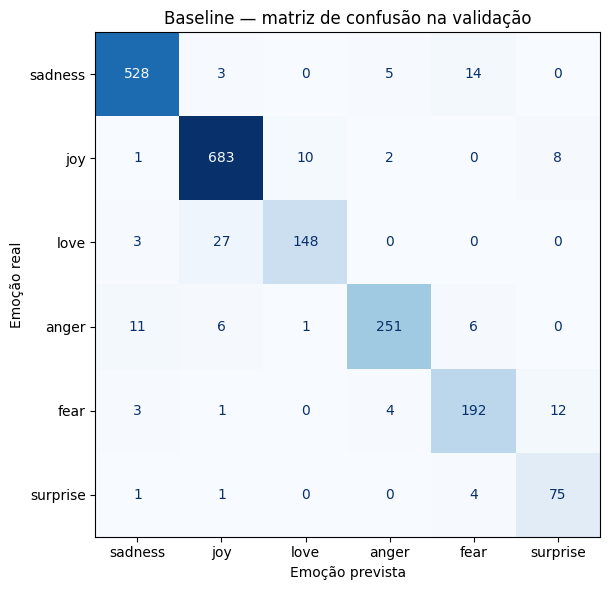

In [12]:
# predict executa inferência e calcula a loss, sem atualizar os pesos.
predicao_validacao = trainer_baseline.predict(
    dataset_tokenizado["validation"],
    metric_key_prefix="validacao",
)
logits_validacao = predicao_validacao.predictions
if isinstance(logits_validacao, tuple):
    logits_validacao = logits_validacao[0]

y_real = predicao_validacao.label_ids
y_previsto = np.argmax(logits_validacao, axis=-1)

metricas_validacao = {
    "loss": float(predicao_validacao.metrics["validacao_loss"]),
    "accuracy": float(accuracy_score(y_real, y_previsto)),
}
for media in ("macro", "weighted"):
    precisao, revocacao, f1, _ = precision_recall_fscore_support(
        y_real, y_previsto, labels=rotulos, average=media, zero_division=0,
    )
    metricas_validacao[f"precision_{media}"] = float(precisao)
    metricas_validacao[f"recall_{media}"] = float(revocacao)
    metricas_validacao[f"f1_{media}"] = float(f1)

display(pd.DataFrame(
    metricas_validacao.items(), columns=["Métrica de validação", "Valor"],
))

relatorio_validacao = classification_report(
    y_real, y_previsto, labels=rotulos, target_names=nomes_classes,
    zero_division=0, output_dict=True,
)
relatorio_validacao_texto = classification_report(
    y_real, y_previsto, labels=rotulos, target_names=nomes_classes,
    zero_division=0, digits=4,
)
print(relatorio_validacao_texto)

matriz_validacao = confusion_matrix(y_real, y_previsto, labels=rotulos)
fig_matriz, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_validacao,
    display_labels=nomes_classes,
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Baseline — matriz de confusão na validação")
ax.set_xlabel("Emoção prevista")
ax.set_ylabel("Emoção real")
fig_matriz.tight_layout()
fig_matriz.savefig(PASTA_BASELINE / "matriz_confusao.png", dpi=150)
plt.show()
plt.close(fig_matriz)


## Evolução da loss e do Macro F1

A loss de treinamento é a média registrada durante cada época com o modelo em treinamento. A loss de validação é calculada ao final da época, sem atualização dos pesos. Os gráficos usam os valores reais do histórico e serão salvos em `results/baseline/`.


,epoch,loss,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.468403,0.205028,0.9285,0.901451
1,2.0,0.154136,0.171134,0.9345,0.908746
2,3.0,0.122701,0.180259,0.9385,0.913975


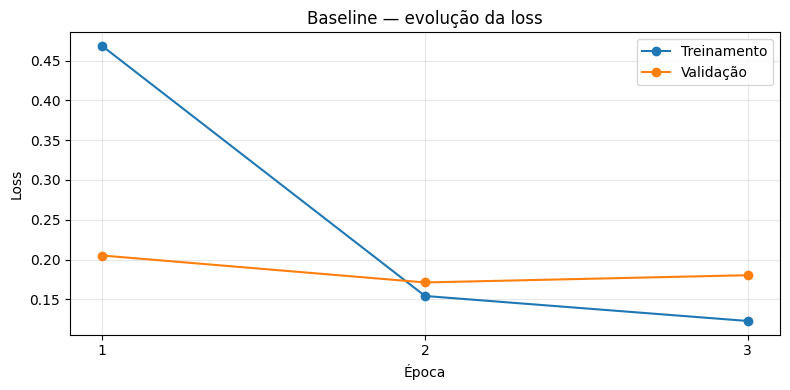

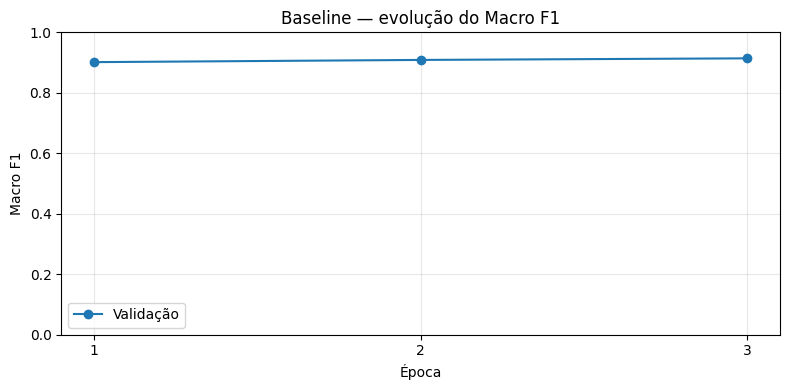

In [13]:
loss_treino = historico_baseline.loc[
    historico_baseline["loss"].notna(), ["epoch", "loss"]
]
evolucao_validacao = historico_baseline.loc[
    historico_baseline["eval_loss"].notna(),
    ["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"],
]
historico_epocas = loss_treino.merge(evolucao_validacao, on="epoch", how="outer")
display(historico_epocas)

fig_loss, ax = plt.subplots(figsize=(8, 4))
ax.plot(loss_treino["epoch"], loss_treino["loss"], marker="o", label="Treinamento")
ax.plot(
    evolucao_validacao["epoch"], evolucao_validacao["eval_loss"],
    marker="o", label="Validação",
)
ax.set(title="Baseline — evolução da loss", xlabel="Época", ylabel="Loss")
ax.set_xticks(range(1, hiperparametros_baseline["epocas"] + 1))
ax.legend()
ax.grid(alpha=0.3)
fig_loss.tight_layout()
fig_loss.savefig(PASTA_BASELINE / "evolucao_loss.png", dpi=150)
plt.show()
plt.close(fig_loss)

fig_f1, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    evolucao_validacao["epoch"], evolucao_validacao["eval_f1_macro"],
    marker="o", label="Validação",
)
ax.set(
    title="Baseline — evolução do Macro F1",
    xlabel="Época", ylabel="Macro F1", ylim=(0, 1),
)
ax.set_xticks(range(1, hiperparametros_baseline["epocas"] + 1))
ax.legend()
ax.grid(alpha=0.3)
fig_f1.tight_layout()
fig_f1.savefig(PASTA_BASELINE / "evolucao_macro_f1.png", dpi=150)
plt.show()
plt.close(fig_f1)


## Salvamento dos resultados do baseline

A próxima célula exporta o melhor modelo e o tokenizer para `results/baseline/melhor_modelo/`. Na pasta do baseline também ficam hiperparâmetros, argumentos do Trainer, versões das bibliotecas, métricas, tempo, histórico completo, resumo por época, relatório por classe e matriz de confusão em formatos reutilizáveis. Os gráficos PNG foram salvos nas células anteriores.

Os checkpoints temporários são removidos somente depois dessas gravações. O modelo exportado serve para inferência e avaliação futura; não preservamos estados do otimizador para retomar o treinamento.

No Colab, copie ou baixe a pasta `results/baseline/` antes de encerrar a sessão, pois o armazenamento local é temporário. Nenhum resultado é preenchido antes da execução real.


In [14]:
# load_best_model_at_end garante que estes são os pesos do melhor checkpoint.
trainer_baseline.save_model(str(PASTA_MODELO))
tokenizer.save_pretrained(str(PASTA_MODELO))


def salvar_json_baseline(nome_arquivo, conteudo):
    (PASTA_BASELINE / nome_arquivo).write_text(
        json.dumps(conteudo, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )


salvar_json_baseline("hiperparametros.json", hiperparametros_baseline)
salvar_json_baseline("metricas_validacao.json", metricas_validacao)
salvar_json_baseline("tempo_treinamento.json", {
    "segundos": tempo_treinamento_segundos,
    "minutos": tempo_treinamento_segundos / 60,
})
salvar_json_baseline("historico_treinamento.json", trainer_baseline.state.log_history)
salvar_json_baseline("relatorio_classificacao.json", relatorio_validacao)
salvar_json_baseline("selecao_melhor_modelo.json", {
    "criterio": "Macro F1 na validação",
    "valor": melhor_f1_validacao,
    "checkpoint_origem": Path(melhor_checkpoint).name,
    "modelo_preservado": str(PASTA_MODELO),
})
salvar_json_baseline("ambiente.json", {
    "bibliotecas": {
        nome: version(nome)
        for nome in ("torch", "transformers", "datasets", "accelerate", "scikit-learn")
    },
    "dispositivo": str(argumentos_baseline.device),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
})
(PASTA_BASELINE / "argumentos_treinamento.json").write_text(
    argumentos_baseline.to_json_string(), encoding="utf-8",
)
(PASTA_BASELINE / "relatorio_classificacao.txt").write_text(
    relatorio_validacao_texto, encoding="utf-8",
)
pd.DataFrame(relatorio_validacao).T.to_csv(
    PASTA_BASELINE / "relatorio_classificacao.csv", index_label="classe",
)
historico_baseline.to_csv(PASTA_BASELINE / "historico_treinamento.csv", index=False)
historico_epocas.to_csv(PASTA_BASELINE / "historico_epocas.csv", index=False)
pd.DataFrame(
    matriz_validacao,
    index=pd.Index(nomes_classes, name="Emoção real"),
    columns=pd.Index(nomes_classes, name="Emoção prevista"),
).to_csv(PASTA_BASELINE / "matriz_confusao.csv")

# Remove somente a pasta temporária criada para os checkpoints desta execução.
checkpoints_temporarios.cleanup()

print("Melhor modelo, tokenizer e resultados salvos em:", PASTA_BASELINE.resolve())
for arquivo in sorted(PASTA_BASELINE.iterdir()):
    print(arquivo.name)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Melhor modelo, tokenizer e resultados salvos em: C:\Users\davis\Documents\vscode\redesNeuraisUC\transformers-rn\results\baseline
ambiente.json
argumentos_treinamento.json
evolucao_loss.png
evolucao_macro_f1.png
hiperparametros.json
historico_epocas.csv
historico_treinamento.csv
historico_treinamento.json
matriz_confusao.csv
matriz_confusao.png
melhor_modelo
metricas_validacao.json
relatorio_classificacao.csv
relatorio_classificacao.json
relatorio_classificacao.txt
selecao_melhor_modelo.json
tempo_treinamento.json


## Como executar o baseline

Execute as células anteriores em ordem e, em seguida:

- **Configuração do baseline:** cria o Trainer e define os hiperparâmetros.
- **Treinamento do baseline:** a chamada `trainer_baseline.train()` realiza o fine-tuning e restaura o melhor modelo.
- **Avaliação do melhor modelo na validação:** a chamada `trainer_baseline.predict(dataset_tokenizado["validation"], metric_key_prefix="validacao")` gera as previsões para métricas e relatório.
- **Evolução da loss e do Macro F1:** apresenta e salva os gráficos.
- **Salvamento dos resultados do baseline:** preserva os artefatos e remove checkpoints temporários.

Para uma nova execução completa, reexecute a partir de **Configuração do baseline**. Ela produzirá um novo treinamento com seed 42 e atualizará os arquivos da pasta de resultados. Variações entre versões de bibliotecas e hardware ainda podem ocorrer. O conjunto de teste permanece reservado para a comparação final.
